In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


In [2]:
data = pd.read_csv("car_evaluation.csv",header = None)
df = pd.DataFrame(data)
df


,0,1,2,3,4,5,6
0,vhigh,vhigh,2,2,small,low,unacc
1,vhigh,vhigh,2,2,small,med,unacc
2,vhigh,vhigh,2,2,small,high,unacc
3,vhigh,vhigh,2,2,med,low,unacc
4,vhigh,vhigh,2,2,med,med,unacc
...,...,...,...,...,...,...,...
1723,low,low,5more,more,med,med,good
1724,low,low,5more,more,med,high,vgood
1725,low,low,5more,more,big,low,unacc
1726,low,low,5more,more,big,med,good


In [3]:
columns = ["buying","mainteinance","doors","persons","bootspace","safety","type"]
df.columns = columns
df.columns

Index(['buying', 'mainteinance', 'doors', 'persons', 'bootspace', 'safety',
       'type'],
      dtype='str')

In [4]:
df.head()

,buying,mainteinance,doors,persons,bootspace,safety,type
0,vhigh,vhigh,2,2,small,low,unacc
1,vhigh,vhigh,2,2,small,med,unacc
2,vhigh,vhigh,2,2,small,high,unacc
3,vhigh,vhigh,2,2,med,low,unacc
4,vhigh,vhigh,2,2,med,med,unacc


In [5]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 1728 entries, 0 to 1727
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   buying        1728 non-null   str  
 1   mainteinance  1728 non-null   str  
 2   doors         1728 non-null   str  
 3   persons       1728 non-null   str  
 4   bootspace     1728 non-null   str  
 5   safety        1728 non-null   str  
 6   type          1728 non-null   str  
dtypes: str(7)
memory usage: 133.5 KB


In [6]:
df.columns

Index(['buying', 'mainteinance', 'doors', 'persons', 'bootspace', 'safety',
       'type'],
      dtype='str')

In [7]:
df.shape

(1728, 7)

In [8]:
df.isna().sum()

buying          0
mainteinance    0
doors           0
persons         0
bootspace       0
safety          0
type            0
dtype: int64

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df.describe()

,buying,mainteinance,doors,persons,bootspace,safety,type
count,1728,1728,1728,1728,1728,1728,1728
unique,4,4,4,3,3,3,4
top,vhigh,vhigh,2,2,small,low,unacc
freq,432,432,432,576,576,576,1210


In [11]:
df.size

12096

In [12]:
for i in columns:
  print(df[i].value_counts())

buying
vhigh    432
high     432
med      432
low      432
Name: count, dtype: int64
mainteinance
vhigh    432
high     432
med      432
low      432
Name: count, dtype: int64
doors
2        432
3        432
4        432
5more    432
Name: count, dtype: int64
persons
2       576
4       576
more    576
Name: count, dtype: int64
bootspace
small    576
med      576
big      576
Name: count, dtype: int64
safety
low     576
med     576
high    576
Name: count, dtype: int64
type
unacc    1210
acc       384
good       69
vgood      65
Name: count, dtype: int64


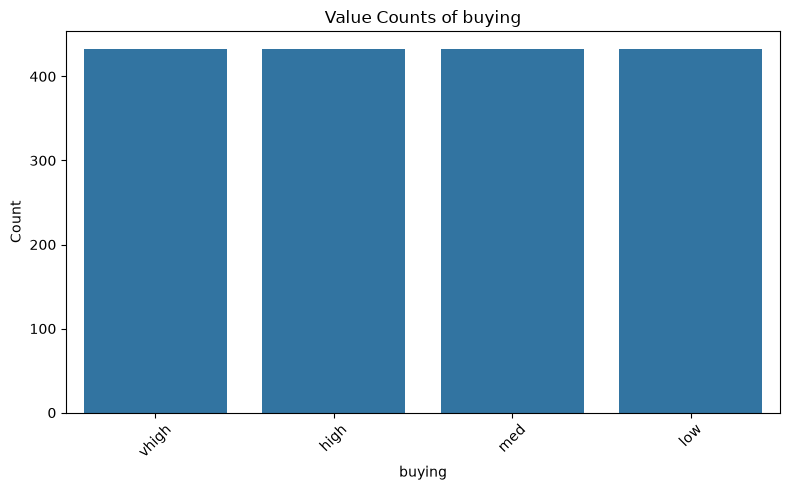

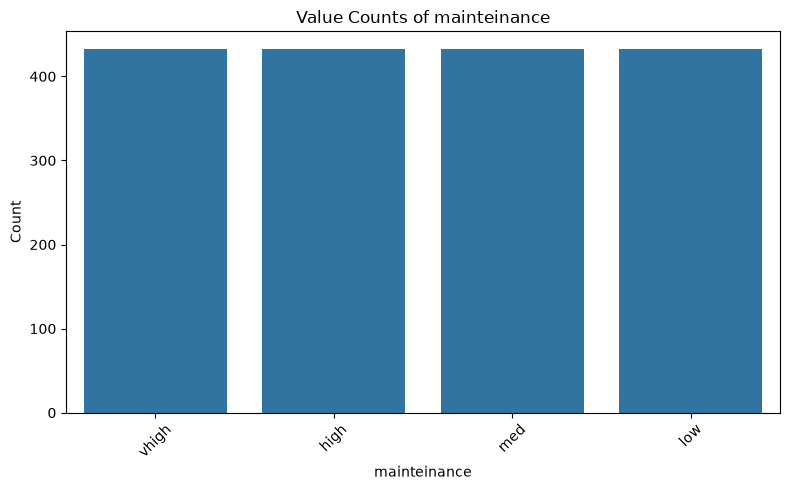

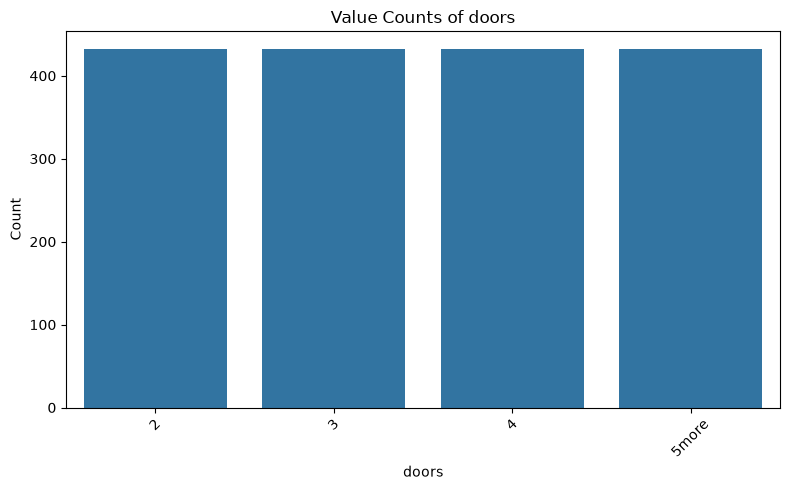

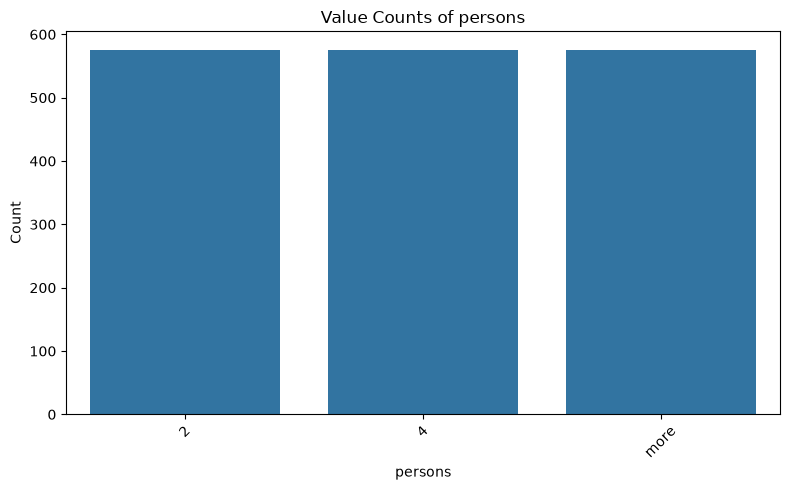

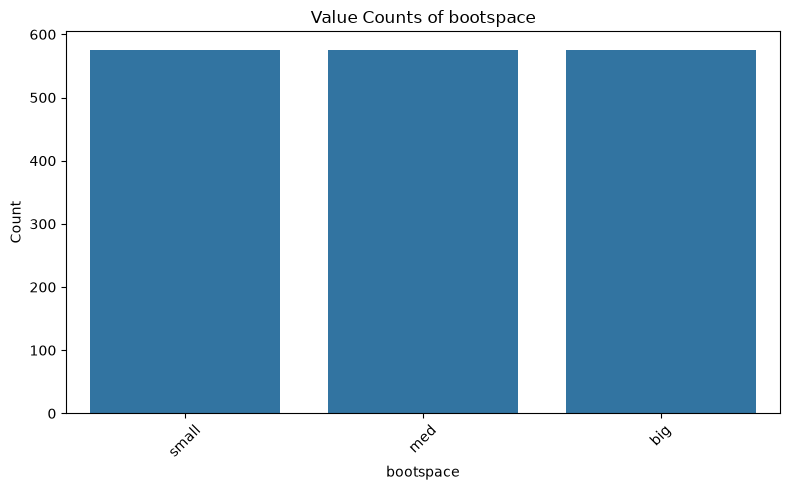

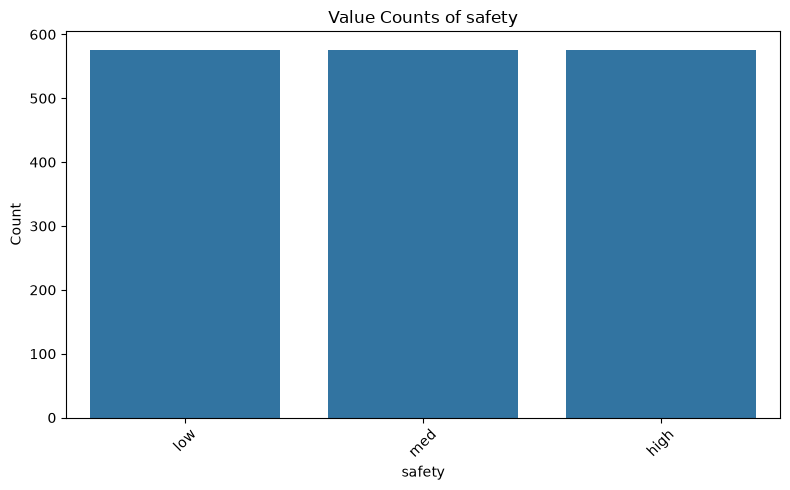

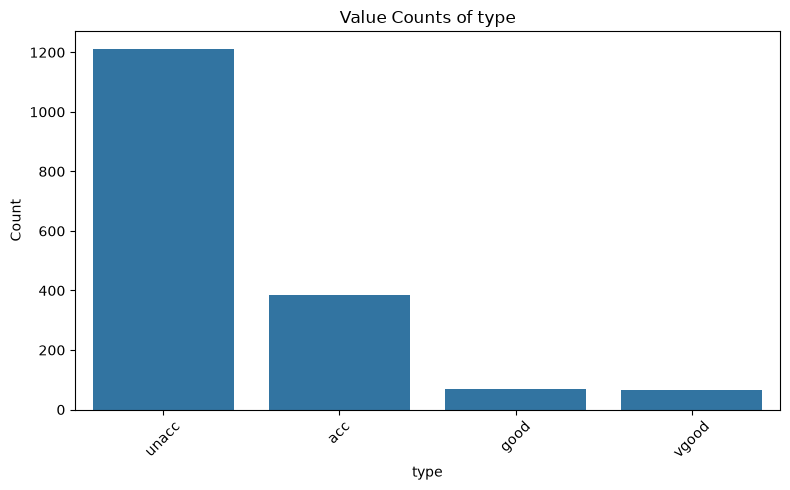

In [13]:
for i in columns:
    plt.figure(figsize=(8, 5))

    sns.countplot(data=df, x=i, order=df[i].value_counts().index)

    plt.title(f"Value Counts of {i}")
    plt.xlabel(i)
    plt.ylabel("Count")
    plt.xticks(rotation=45)

    plt.tight_layout()
    plt.show()

In [14]:
df.columns

Index(['buying', 'mainteinance', 'doors', 'persons', 'bootspace', 'safety',
       'type'],
      dtype='str')

In [15]:
X = df.drop("type",axis=1)
y = df["type"]

In [16]:
from sklearn.preprocessing import OrdinalEncoder
oe = OrdinalEncoder()
X = oe.fit_transform(X)
X


array([[3., 3., 0., 0., 2., 1.],
       [3., 3., 0., 0., 2., 2.],
       [3., 3., 0., 0., 2., 0.],
       ...,
       [1., 1., 3., 2., 0., 1.],
       [1., 1., 3., 2., 0., 2.],
       [1., 1., 3., 2., 0., 0.]], shape=(1728, 6))

In [17]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state= 42)


In [18]:
from sklearn.ensemble import RandomForestClassifier
model = RandomForestClassifier(random_state=42,n_estimators = 200)
model.fit(X_train,y_train)
y_pred = model.predict(X_test)
y_pred

array(['unacc', 'unacc', 'unacc', 'acc', 'unacc', 'acc', 'unacc', 'unacc',
       'unacc', 'unacc', 'vgood', 'good', 'unacc', 'unacc', 'unacc',
       'unacc', 'unacc', 'unacc', 'unacc', 'acc', 'unacc', 'acc', 'acc',
       'unacc', 'acc', 'unacc', 'unacc', 'unacc', 'unacc', 'unacc', 'acc',
       'unacc', 'unacc', 'unacc', 'acc', 'acc', 'good', 'unacc', 'unacc',
       'unacc', 'unacc', 'unacc', 'acc', 'acc', 'good', 'acc', 'unacc',
       'unacc', 'unacc', 'unacc', 'unacc', 'unacc', 'acc', 'unacc',
       'unacc', 'unacc', 'unacc', 'unacc', 'unacc', 'good', 'unacc',
       'acc', 'unacc', 'unacc', 'acc', 'vgood', 'unacc', 'acc', 'acc',
       'unacc', 'unacc', 'unacc', 'unacc', 'unacc', 'good', 'vgood',
       'unacc', 'unacc', 'unacc', 'unacc', 'vgood', 'unacc', 'unacc',
       'acc', 'vgood', 'acc', 'unacc', 'acc', 'vgood', 'acc', 'unacc',
       'good', 'unacc', 'unacc', 'unacc', 'good', 'unacc', 'unacc',
       'unacc', 'acc', 'unacc', 'unacc', 'unacc', 'unacc', 'unacc',
       '

In [19]:
from sklearn.metrics import accuracy_score

print(accuracy_score(y_test,y_pred))

0.9710982658959537


In [20]:
from sklearn.metrics import confusion_matrix

print(confusion_matrix(y_test,y_pred))

[[ 74   6   3   0]
 [  0  11   0   0]
 [  0   0 235   0]
 [  1   0   0  16]]


In [21]:
from sklearn.metrics import classification_report

print(classification_report(y_pred,y_test))


              precision    recall  f1-score   support

         acc       0.89      0.99      0.94        75
        good       1.00      0.65      0.79        17
       unacc       1.00      0.99      0.99       238
       vgood       0.94      1.00      0.97        16

    accuracy                           0.97       346
   macro avg       0.96      0.91      0.92       346
weighted avg       0.97      0.97      0.97       346

